# 05 - Final Evaluation (integrity audit)
Goal: find out whether our earlier scores (Voting test R² ≈ 0.925) are trustworthy, and get a **clean final estimate**.

What is different from notebooks 03/04:
1. Exact duplicate rows are removed **before** splitting.
2. Laptops with an **identical specification** (same config, different listed price) are kept, but always placed on the
   **same side** of every split (group-aware split + group-aware CV), so the model is never tested on a configuration it saw in training.
3. A **fresh holdout set** (new seed) is created and not touched until all tuning and model selection is finished.
4. Only the three serious candidates are compared: XGBoost, Gradient Boosting, Voting (XGB + GB + HistGB + RF).

No production model is saved in this notebook, and no existing file is modified.

In [1]:
import re
import io
import time
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, KFold, RepeatedKFold,
                                     RandomizedSearchCV, cross_validate, train_test_split)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, make_scorer
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor)
from xgboost import XGBRegressor

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 40)
warnings.filterwarnings('ignore', category=UserWarning)

# ---- Documented seeds ----
SPLIT_SEED = 42      # NEW holdout split (notebooks 02-04 used random_state=2 with test_size=0.15)
TEST_SIZE = 0.20     # fraction of configuration groups held out
CV_SEED = 7          # seed for the tuning CV folds on the training portion
MODEL_SEED = 2       # random_state inside the models (same as before)

# Chart style used in earlier notebooks
BLUE, INK, INK2, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e6e6e3'
def style(ax, grid_axis='y'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
rupees = plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k')

## 1. Duplicate rows (checked on the RAW data, before any feature engineering)

In [2]:
raw_full = pd.read_csv('laptop_data.csv')
print('Raw rows:', len(raw_full), '| columns:', raw_full.shape[1])

# 'Unnamed: 0' is an exported row index (0..n-1). Its unique values would hide duplicates, so check and drop it.
assert (raw_full['Unnamed: 0'] == np.arange(len(raw_full))).all()
raw_full = raw_full.drop(columns=['Unnamed: 0'])

SPEC_COLS = [c for c in raw_full.columns if c != 'Price']   # every column except the target
exact_dup_mask = raw_full.duplicated(keep='first')           # all 11 columns identical, including Price
in_exact_group = raw_full.duplicated(keep=False)
print('Exact duplicate copies (extra rows beyond the first):', exact_dup_mask.sum())
print('Rows that belong to an exact-duplicate group:        ', in_exact_group.sum())
group_sizes = raw_full[in_exact_group].groupby(list(raw_full.columns)).size()
print('Exact-duplicate groups:', len(group_sizes), '| group sizes:', group_sizes.value_counts().sort_index().to_dict())

Raw rows: 1303 | columns: 12
Exact duplicate copies (extra rows beyond the first): 29
Rows that belong to an exact-duplicate group:         43
Exact-duplicate groups: 14 | group sizes: {3: 13, 4: 1}


In [3]:
# Examples of exact-duplicate groups (the original row number is shown on the left)
examples = raw_full[in_exact_group].sort_values(SPEC_COLS)
examples.head(9)

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1263,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.9200
1277,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.9200
1291,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.9200
1172,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1274,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1288,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1302,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1269,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4GB,500GB HDD,Nvidia GeForce 920M,Windows 10,2.2kg,38378.6496
1283,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4GB,500GB HDD,Nvidia GeForce 920M,Windows 10,2.2kg,38378.6496


In [4]:
# Do exact duplicates share the same Price? (By definition yes - verify explicitly)
price_per_group = raw_full[in_exact_group].groupby(SPEC_COLS)['Price'].nunique()
print('Exact-duplicate groups with more than one Price:', (price_per_group > 1).sum())

# Same configuration (all spec columns identical) but DIFFERENT price?
spec_dup = raw_full[raw_full.duplicated(subset=SPEC_COLS, keep=False)]
spec_groups = spec_dup.groupby(SPEC_COLS)['Price'].agg(['count', 'nunique', 'min', 'max'])
diff_price = spec_groups[spec_groups['nunique'] > 1]
print('Configuration groups that appear more than once:     ', len(spec_groups))
print('...of which have DIFFERENT prices:                   ', len(diff_price))
ratio = diff_price['max'] / diff_price['min']
print(f'Price gap inside those groups (max/min): median {ratio.median():.3f}, max {ratio.max():.3f}')

Exact-duplicate groups with more than one Price: 0
Configuration groups that appear more than once:      59
...of which have DIFFERENT prices:                    45
Price gap inside those groups (max/min): median 1.086, max 1.721


In [5]:
# Examples: identical specification, different price
spec_dup[spec_dup.set_index(SPEC_COLS).index.isin(diff_price.index)].sort_values(SPEC_COLS).head(8)

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
543,Acer,Gaming,15.6,Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,Linux,2.4kg,42517.440
651,Acer,Gaming,15.6,Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,Linux,2.4kg,37775.520
644,Acer,Notebook,15.6,1366x768,Intel Core i3 6006U 2GHz,4GB,500GB HDD,Intel HD Graphics 520,Windows 10,2.4kg,23976.000
739,Acer,Notebook,15.6,1366x768,Intel Core i3 6006U 2GHz,4GB,500GB HDD,Intel HD Graphics 520,Windows 10,2.4kg,21887.424
210,Acer,Notebook,15.6,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,Linux,2.4kg,41505.120
379,Acer,Notebook,15.6,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,Linux,2.4kg,45074.880
211,Asus,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1050,Windows 10,2.9kg,74964.960
401,Asus,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1050,Windows 10,2.9kg,81465.120


**What these are**
* **Exact duplicates** (all columns including `Price` identical) are almost certainly the same listing scraped more than once.
  They add no information, so the extra copies are removed.
* **Same-spec / different-price** rows are *not* errors: the same model listed at different prices (seller, date, variant).
  They are real observations of price noise, so they are **kept**. But they must not be split across train and test.

**Why duplicates across train and test inflate scores:** if an identical copy of a test laptop is in the training set, a flexible model
(boosted trees, random forest) can essentially memorise its price. The test score then measures *recall of seen laptops*, not
*prediction for new laptops*, which is what the website needs. The same applies, to a smaller degree, to identical configurations with
slightly different prices.

In [6]:
# Remove the ARM row (same rule as notebooks 02-04), then remove exact duplicate copies
n0 = len(raw_full)
arm_mask = raw_full['Gpu'].str.startswith('ARM')
print('ARM rows:'); print(raw_full[arm_mask][SPEC_COLS + ['Price']].to_string())
assert not (arm_mask & in_exact_group).any(), 'ARM row is not part of a duplicate group'

raw = raw_full[~arm_mask].copy()
raw['row_id'] = np.arange(len(raw))    # position after ARM removal = row index in laptop_clean.csv / old split
n1 = len(raw)
raw = raw[~raw.duplicated(subset=SPEC_COLS + ['Price'], keep='first')].reset_index(drop=True)
n2 = len(raw)

print(f'\nRaw rows:                         {n0}')
print(f'After removing ARM row:           {n1}  (-{n0 - n1})')
print(f'After removing exact duplicates:  {n2}  (-{n1 - n2})')
print('Remaining exact duplicates:', raw.duplicated(subset=SPEC_COLS + ['Price']).sum())
print('Unique configurations (groups):', raw.groupby(SPEC_COLS).ngroup().nunique())

ARM rows:
      Company            TypeName  Inches                 ScreenResolution                            Cpu  Ram              Memory                Gpu      OpSys  Weight     Price
1191  Samsung  2 in 1 Convertible    12.3  IPS Panel Touchscreen 2400x1600  Samsung Cortex A72&A53 2.0GHz  4GB  32GB Flash Storage  ARM Mali T860 MP4  Chrome OS  1.15kg  35111.52

Raw rows:                         1303
After removing ARM row:           1302  (-1)
After removing exact duplicates:  1273  (-29)
Remaining exact duplicates: 0
Unique configurations (groups): 1228


## 2. Rebuild the final feature set (same code as notebook 04)
The functions are copied from notebook 04 unchanged. To make target leakage **structurally impossible**, the features are built from a
copy of the raw data **with the `Price` column removed**.

In [7]:
raw_X = raw.drop(columns=['Price'])     # the feature builder never sees Price

def cpu_brand(text):
    name = ' '.join(text.split()[:3])
    if name in ('Intel Core i7', 'Intel Core i5', 'Intel Core i3'):
        return name
    return 'Other Intel Processor' if name.split()[0] == 'Intel' else 'AMD Processor'

def parse_memory(text):
    sizes = {'SSD': 0, 'HDD': 0, 'Flash Storage': 0, 'Hybrid': 0}
    for part in text.split('+'):
        size, unit, kind = re.fullmatch(r'(\d+(?:\.\d+)?)(GB|TB) (SSD|HDD|Flash Storage|Hybrid)', part.strip()).groups()
        sizes[kind] += int(float(size) * (1000 if unit == 'TB' else 1))
    return pd.Series(sizes)

def cpu_type(text):
    if re.search(r'\d{4}H[QK]\b', text):
        return 'High-performance (H)'
    if re.search(r'\d{4}U\b', text):
        return 'Low-power (U)'
    if re.search(r'\dY\d{2}', text):
        return 'Ultra-low-power (Y)'
    return 'Other'

def cpu_gen(text):
    m = re.search(r'Intel Core (?:i\d|M) (?:[mM]\d-)?(\d)(?:\d{3}|Y\d{2})', text)
    return f'Gen {m.group(1)}' if m else 'Unknown'

def gpu_tier(text):
    if 'GTX' in text:                          return 'Nvidia GTX'
    if 'Quadro' in text:                       return 'Nvidia Quadro'
    if text.startswith('Nvidia'):              return 'Nvidia other (MX/GT/9xxMX)'
    if 'FirePro' in text or 'Radeon Pro' in text: return 'AMD Pro/FirePro'
    if text.startswith('AMD'):                 return 'AMD other'
    if 'Iris' in text:                         return 'Intel Iris'
    return 'Intel HD/UHD'

def build_features(r):
    d = pd.DataFrame(index=r.index)
    d['Company'] = r['Company']
    d['TypeName'] = r['TypeName']
    d['Ram'] = r['Ram'].str.replace('GB', '', regex=False).astype(int)
    d['Weight'] = r['Weight'].str.replace('kg', '', regex=False).astype(float)
    d['Touchscreen'] = r['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)
    d['Ips'] = r['ScreenResolution'].str.contains('IPS', case=False).astype(int)
    res = r['ScreenResolution'].str.split('x', n=1, expand=True)
    d['X_res'] = res[0].str.extract(r'(\d+)$')[0].astype(int)
    d['Y_res'] = res[1].astype(int)
    d['Inches'] = r['Inches']
    d['ppi'] = np.sqrt(d['X_res'] ** 2 + d['Y_res'] ** 2) / d['Inches']
    d['Cpu brand'] = r['Cpu'].apply(cpu_brand)
    mem = r['Memory'].apply(parse_memory)
    d['SSD'], d['HDD'] = mem['SSD'], mem['HDD']
    d['Gpu brand'] = r['Gpu'].str.split().str[0]
    d['os'] = r['OpSys'].map(lambda s: 'Windows' if s in ('Windows 10', 'Windows 7', 'Windows 10 S')
                             else 'Mac' if s in ('macOS', 'Mac OS X') else 'Others/No OS/Linux')
    d['cpu_ghz'] = r['Cpu'].str.extract(r'([\d.]+)GHz')[0].astype(float)
    d['cpu_type'] = r['Cpu'].apply(cpu_type)
    d['cpu_gen'] = r['Cpu'].apply(cpu_gen)
    d['gpu_tier'] = r['Gpu'].apply(gpu_tier)
    return d

d = build_features(raw_X)
y = np.log(raw['Price'])                 # target, kept completely separate
price = raw['Price']
print('Feature table:', d.shape)

Feature table: (1273, 19)


### Verify every engineered feature

In [8]:
# (a) The 12 original features must equal laptop_clean.csv (notebook 02) for the same rows
clean = pd.read_csv('laptop_clean.csv')
orig_cols = [c for c in clean.columns if c != 'Price']
pd.testing.assert_frame_equal(d[orig_cols].reset_index(drop=True),
                              clean.loc[raw['row_id'], orig_cols].reset_index(drop=True), check_dtype=False)
assert np.allclose(price.values, clean.loc[raw['row_id'], 'Price'].values)
print('Original features match laptop_clean.csv for all', len(d), 'kept rows')

# (b) No missing values and sensible ranges
assert d.isnull().sum().sum() == 0
print(d[['Ram', 'Weight', 'ppi', 'SSD', 'HDD', 'cpu_ghz', 'Inches', 'X_res', 'Y_res']].describe().loc[['min', 'max']].round(2))

# (c) ppi is recomputable from its inputs
assert np.allclose(d['ppi'], np.hypot(d['X_res'], d['Y_res']) / d['Inches'])
# (d) cpu_ghz matches the number written in the Cpu string, e.g. '... 2.5GHz'
last_token = raw_X['Cpu'].str.split().str[-1]
assert last_token.str.endswith('GHz').all()
assert np.allclose(last_token.str.replace('GHz', '', regex=False).astype(float), d['cpu_ghz'])
print('ppi and cpu_ghz verified against the raw strings')

Original features match laptop_clean.csv for all 1273 kept rows
      Ram  Weight     ppi     SSD     HDD  cpu_ghz  Inches   X_res   Y_res
min   2.0    0.69   90.58     0.0     0.0      0.9    10.1  1366.0   768.0
max  64.0    4.70  352.47  1024.0  2000.0      3.6    18.4  3840.0  2160.0
ppi and cpu_ghz verified against the raw strings


In [9]:
# (e) Spot-check the regex-based categories: which raw CPU strings fall into each class?
for col in ['cpu_type', 'cpu_gen']:
    print(f'--- {col} ---')
    for cls, grp in raw_X.groupby(d[col])['Cpu']:
        sample = grp.str.replace(r' [\d.]+GHz', '', regex=True).value_counts().index[:4].tolist()
        print(f'{cls:<22} n={len(grp):<4} e.g. {sample}')
print('--- gpu_tier ---')
for cls, grp in raw_X.groupby(d['gpu_tier'])['Gpu']:
    print(f'{cls:<28} n={len(grp):<4} e.g. {grp.value_counts().index[:4].tolist()}')

--- cpu_type ---
High-performance (H)   n=264  e.g. ['Intel Core i7 7700HQ', 'Intel Core i7 6700HQ', 'Intel Core i5 7300HQ', 'Intel Core i7 6820HK']
Low-power (U)          n=790  e.g. ['Intel Core i5 7200U', 'Intel Core i7 7500U', 'Intel Core i3 6006U', 'Intel Core i7 8550U']
Other                  n=197  e.g. ['Intel Celeron Dual Core N3350', 'Intel Celeron Dual Core N3060', 'Intel Pentium Quad Core N4200', 'Intel Core i5']
Ultra-low-power (Y)    n=22   e.g. ['Intel Core M 6Y75', 'Intel Core i7 7Y75', 'Intel Core i5 7Y54', 'Intel Core i5 7Y57']
--- cpu_gen ---
Gen 6                  n=310  e.g. ['Intel Core i3 6006U', 'Intel Core i5 6200U', 'Intel Core i7 6500U', 'Intel Core i7 6700HQ']
Gen 7                  n=611  e.g. ['Intel Core i5 7200U', 'Intel Core i7 7700HQ', 'Intel Core i7 7500U', 'Intel Core i3 7100U']
Gen 8                  n=147  e.g. ['Intel Core i7 8550U', 'Intel Core i5 8250U', 'Intel Core i7 8650U']
Unknown                n=205  e.g. ['Intel Celeron Dual Core N3350', 

In [10]:
# (f) cpu_gen = 'Unknown' should only be CPUs WITHOUT a readable Intel Core generation (AMD, Atom, Celeron, Pentium, Xeon, Core M...)
unknown = raw_X.loc[d['cpu_gen'] == 'Unknown', 'Cpu'].str.split().str[:3].str.join(' ').value_counts()
print(unknown.to_string())
assert not raw_X.loc[d['cpu_gen'] == 'Unknown', 'Cpu'].str.contains(r'Intel Core i\d \d{4}', regex=True).any()

Cpu
Intel Celeron Dual          69
Intel Pentium Quad          27
Intel Core i5               12
AMD A9-Series 9420          12
AMD A6-Series 9220           8
Intel Celeron Quad           8
AMD A12-Series 9720P         7
Intel Core M                 5
Intel Atom x5-Z8350          5
Intel Core i7                4
Intel Atom x5-Z8550          4
AMD A8-Series 7410           4
AMD Ryzen 1700               3
Intel Pentium Dual           3
AMD E-Series E2-9000e        2
Intel Xeon E3-1505M          2
AMD A10-Series A10-9620P     2
AMD A6-Series A6-9220        2
AMD A10-Series 9600P         2
AMD A10-Series 9620P         2
AMD E-Series 7110            2
AMD A9-Series A9-9420        2
Intel Xeon E3-1535M          2
Intel Atom X5-Z8350          2
Intel Atom x5-Z8300          1
AMD E-Series E2-6110         1
AMD FX 9830P                 1
AMD E-Series 6110            1
AMD E-Series 9000e           1
AMD Ryzen 1600               1
AMD E-Series E2-9000         1
AMD A6-Series 7310           1
Inte

**Target-leakage check for features:** every feature is a deterministic function of the laptop's own specification strings.
The builder received `raw_X` (no `Price` column), so no feature can contain price information. The only data-dependent rule,
`Company_grouped` (rare brands -> "Other"), is decided below from **training-row counts only** and uses no prices at all.

## 3. Fresh evaluation protocol
* **Groups** = unique full specification (all raw columns except Price). Same-spec laptops always stay together.
* **Holdout**: `GroupShuffleSplit(test_size=0.20, random_state=42)`. It is not used again until section 5.
* **Tuning/model selection**: `GroupKFold(5, shuffle, random_state=7)` on the training portion only.

In [11]:
groups = raw.groupby(SPEC_COLS).ngroup()

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SPLIT_SEED)
train_pos, test_pos = next(gss.split(d, y, groups))
idx_train, idx_test = d.index[train_pos], d.index[test_pos]

print(f'Usable observations: {len(d)}  ({groups.nunique()} unique configurations)')
print(f'Train: {len(idx_train)} rows ({groups[idx_train].nunique()} configs)')
print(f'Final holdout: {len(idx_test)} rows ({groups[idx_test].nunique()} configs)  = {len(idx_test)/len(d):.1%}')

# Company_grouped: rare-brand list decided from TRAINING rows only (counts, never prices)
company_counts_train = d.loc[idx_train, 'Company'].value_counts()
rare_companies = company_counts_train[company_counts_train < 10].index.tolist()
d['Company_grouped'] = d['Company'].where(~d['Company'].isin(rare_companies), 'Other')
print('Grouped into Other (from train counts):', rare_companies)

FINAL_CAT = ['TypeName', 'Cpu brand', 'os', 'cpu_type', 'cpu_gen', 'gpu_tier', 'Company_grouped']
FINAL_NUM = ['Ram', 'Weight', 'Touchscreen', 'Ips', 'ppi', 'SSD', 'HDD', 'cpu_ghz', 'Inches', 'X_res', 'Y_res']
FEATURES = FINAL_CAT + FINAL_NUM
X_train, X_test = d.loc[idx_train, FEATURES], d.loc[idx_test, FEATURES]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
g_train = groups.loc[idx_train]
print('Features used:', len(FEATURES))

Usable observations: 1273  (1228 unique configurations)
Train: 1015 rows (982 configs)
Final holdout: 258 rows (246 configs)  = 20.3%
Grouped into Other (from train counts): ['Microsoft', 'Razer', 'Mediacom', 'Xiaomi', 'Vero', 'Samsung', 'Google', 'LG', 'Huawei', 'Chuwi', 'Fujitsu']
Features used: 18


In [12]:
# How does the new holdout relate to the OLD split (notebooks 02-04: test_size=0.15, random_state=2 on 1302 rows)?
old_train_ids, old_test_ids = train_test_split(np.arange(1302), test_size=0.15, random_state=2)
new_test_ids = raw.loc[idx_test, 'row_id']
print('New holdout rows that were in the OLD test set: ', new_test_ids.isin(old_test_ids).sum())
print('New holdout rows that were in the OLD train set:', new_test_ids.isin(old_train_ids).sum())
print('Note: the feature set and search spaces were chosen in notebook 04 using CV on the OLD training rows,')
print('so this holdout is fresh for model fitting and tuning, but not 100% independent of earlier feature decisions.')

New holdout rows that were in the OLD test set:  47
New holdout rows that were in the OLD train set: 211
Note: the feature set and search spaces were chosen in notebook 04 using CV on the OLD training rows,
so this holdout is fresh for model fitting and tuning, but not 100% independent of earlier feature decisions.


## 4. Tune the candidates (training portion only, group-aware 5-fold CV)
Same search spaces as notebooks 03/04 (RandomizedSearchCV, 40 combinations each). HistGB and RF are tuned only because they are
members of the Voting ensemble.

In [13]:
def make_pipe(model):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), FINAL_CAT),
        ('num', 'passthrough', FINAL_NUM),
    ])
    return Pipeline([('preprocess', pre), ('model', model)])

# Fixed list of folds so every model is tuned/scored on exactly the same group-aware folds
tune_folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=CV_SEED).split(X_train, y_train, g_train))

search_spaces = {
    'Gradient Boosting': (GradientBoostingRegressor(random_state=MODEL_SEED), {
        'model__n_estimators': [200, 400, 700, 1000], 'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [2, 3, 4, 5, 6], 'model__subsample': [0.6, 0.8, 1.0],
        'model__max_features': [0.3, 0.5, 0.75, None], 'model__min_samples_leaf': [1, 3, 5]}),
    'Hist Gradient Boosting': (HistGradientBoostingRegressor(random_state=MODEL_SEED), {
        'model__learning_rate': [0.02, 0.05, 0.1], 'model__max_iter': [200, 400, 700],
        'model__max_leaf_nodes': [8, 15, 31, 63], 'model__min_samples_leaf': [5, 10, 20],
        'model__l2_regularization': [0.0, 0.1, 1.0]}),
    'XGBoost': (XGBRegressor(random_state=MODEL_SEED, n_jobs=1, tree_method='hist'), {
        'model__n_estimators': [300, 500, 800, 1200], 'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [3, 4, 5, 6, 8], 'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.4, 0.6, 0.8, 1.0], 'model__min_child_weight': [1, 3, 5],
        'model__reg_lambda': [0.5, 1, 5]}),
    'Random Forest': (RandomForestRegressor(random_state=MODEL_SEED, n_jobs=1), {
        'model__n_estimators': [200, 400, 600], 'model__max_depth': [None, 10, 15, 20],
        'model__max_features': [0.3, 0.5, 0.75, 1.0], 'model__min_samples_leaf': [1, 2, 4],
        'model__max_samples': [None, 0.5, 0.75]}),
}

tuned, tune_cv = {}, {}
for name, (model, grid) in search_spaces.items():
    start = time.time()
    search = RandomizedSearchCV(make_pipe(model), grid, n_iter=40, cv=tune_folds, scoring='r2', n_jobs=-1, random_state=MODEL_SEED)
    search.fit(X_train, y_train)          # holdout is not passed anywhere
    tuned[name] = search.best_estimator_
    tune_cv[name] = search.best_score_
    params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    print(f'{name:<24} tuning CV R2 = {search.best_score_:.4f}  ({time.time() - start:.0f}s)  {params}')

candidates = {
    'XGBoost': tuned['XGBoost'],
    'Gradient Boosting': tuned['Gradient Boosting'],
    'Voting (XGB+GB+HistGB+RF)': VotingRegressor([(n, clone(tuned[n])) for n in search_spaces], n_jobs=1),
}

Gradient Boosting        tuning CV R2 = 0.8994  (20s)  {'subsample': 0.6, 'n_estimators': 700, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 4, 'learning_rate': 0.02}


Hist Gradient Boosting   tuning CV R2 = 0.8926  (25s)  {'min_samples_leaf': 5, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 1.0}


XGBoost                  tuning CV R2 = 0.9027  (7s)  {'subsample': 0.8, 'reg_lambda': 0.5, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.4}


Random Forest            tuning CV R2 = 0.8851  (22s)  {'n_estimators': 600, 'min_samples_leaf': 1, 'max_samples': 0.75, 'max_features': 0.3, 'max_depth': 15}


## 6. Robustness: repeated group-aware CV on the training portion
5 folds x 5 repeats = 25 scores per model, with **different fold seeds from tuning**. Metrics:
* R² on log(Price)
* R² on Price (predictions converted back with `exp`)
* MAE in rupees

Caveat: the hyperparameters were tuned on this same training data, so these CV numbers can be slightly optimistic. The holdout
(section 5) is the unbiased check.

*(This is done before the holdout evaluation on purpose, so the holdout cannot influence the choice.)*

In [14]:
def price_r2(y_true_log, y_pred_log):
    return r2_score(np.exp(y_true_log), np.exp(y_pred_log))
def price_mae(y_true_log, y_pred_log):
    return mean_absolute_error(np.exp(y_true_log), np.exp(y_pred_log))
cv_scoring = {'r2_log': 'r2', 'r2_price': make_scorer(price_r2), 'mae_price': make_scorer(price_mae)}

REPEATS = 5
rep_folds = []
for rep in range(REPEATS):
    rep_folds += list(GroupKFold(n_splits=5, shuffle=True, random_state=100 + rep).split(X_train, y_train, g_train))

cv_raw = {}
for name, est in candidates.items():
    start = time.time()
    res = cross_validate(clone(est), X_train, y_train, cv=rep_folds, scoring=cv_scoring, n_jobs=-1)
    cv_raw[name] = pd.DataFrame({k.replace('test_', ''): v for k, v in res.items() if k.startswith('test_')})
    print(f'{name:<28} done in {time.time() - start:.0f}s')

cv_summary = pd.DataFrame({
    name: {'CV R2 log (mean)': s['r2_log'].mean(), 'CV R2 log (std)': s['r2_log'].std(),
           'CV R2 price (mean)': s['r2_price'].mean(), 'CV R2 price (std)': s['r2_price'].std(),
           'CV MAE Rs (mean)': s['mae_price'].mean(), 'CV MAE Rs (std)': s['mae_price'].std()}
    for name, s in cv_raw.items()}).T
cv_summary.round(4)

XGBoost                      done in 1s


Gradient Boosting            done in 2s


Voting (XGB+GB+HistGB+RF)    done in 11s


,CV R2 log (mean),CV R2 log (std),CV R2 price (mean),CV R2 price (std),CV MAE Rs (mean),CV MAE Rs (std)
XGBoost,0.8974,0.0138,0.8203,0.0481,9564.8638,1001.5546
Gradient Boosting,0.8951,0.0136,0.8266,0.0415,9728.3619,1067.1049
Voting (XGB+GB+HistGB+RF),0.8959,0.0129,0.8251,0.0411,9659.8155,1032.2946


In [15]:
# Paired comparison: same 25 folds for every model, so compare fold by fold
vote, xgb, gb = cv_raw['Voting (XGB+GB+HistGB+RF)'], cv_raw['XGBoost'], cv_raw['Gradient Boosting']
paired = pd.DataFrame({
    'Voting - XGBoost': [(vote['r2_log'] - xgb['r2_log']).mean(), (vote['r2_log'] - xgb['r2_log']).std(),
                         ((vote['r2_log'] - xgb['r2_log']) > 0).mean(), (vote['mae_price'] - xgb['mae_price']).mean()],
    'Voting - Gradient Boosting': [(vote['r2_log'] - gb['r2_log']).mean(), (vote['r2_log'] - gb['r2_log']).std(),
                                   ((vote['r2_log'] - gb['r2_log']) > 0).mean(), (vote['mae_price'] - gb['mae_price']).mean()],
    'XGBoost - Gradient Boosting': [(xgb['r2_log'] - gb['r2_log']).mean(), (xgb['r2_log'] - gb['r2_log']).std(),
                                    ((xgb['r2_log'] - gb['r2_log']) > 0).mean(), (xgb['mae_price'] - gb['mae_price']).mean()],
}, index=['Mean R2 diff', 'Std of R2 diff', 'Share of folds first is better', 'Mean MAE diff (Rs)']).T
paired.round(4)

,Mean R2 diff,Std of R2 diff,Share of folds first is better,Mean MAE diff (Rs)
Voting - XGBoost,-0.0014,0.0034,0.20,94.9517
Voting - Gradient Boosting,0.0009,0.0034,0.64,-68.5464
XGBoost - Gradient Boosting,0.0023,0.0057,0.64,-163.4981


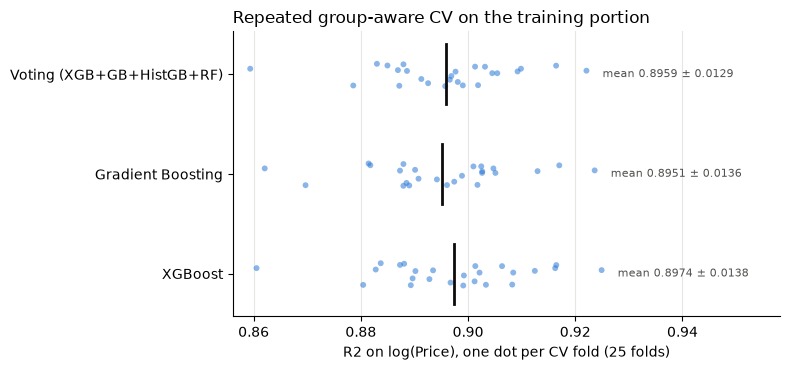

In [16]:
# Chart: the 25 fold scores per model (spread = how much a single lucky/unlucky split can move the score)
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(cv_raw)
for i, name in enumerate(names):
    s = cv_raw[name]['r2_log']
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(s))
    ax.scatter(s, np.full(len(s), i) + jitter, s=18, color=BLUE, alpha=0.55, edgecolor='none')
    ax.plot([s.mean()] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=2)
    ax.text(s.max() + 0.003, i, f'mean {s.mean():.4f} ± {s.std():.4f}', va='center', fontsize=8, color=INK2)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel('R2 on log(Price), one dot per CV fold (25 folds)')
ax.set_title('Repeated group-aware CV on the training portion', loc='left')
style(ax, 'x')
ax.set_xlim(right=ax.get_xlim()[1] + 0.03)
plt.tight_layout()
fig.savefig('final_cv_stability.png', dpi=120, bbox_inches='tight')
plt.show()

### How much did duplicates inflate the old estimates?
One XGBoost configuration (the best from notebook 04), same features, 5x3 repeated CV, under three protocols:
1. **Old protocol**: all 1302 rows (duplicates included), plain random KFold.
2. Exact duplicates removed, plain random KFold.
3. Exact duplicates removed and same-spec rows grouped (the protocol used in this notebook).

In [17]:
xgb_04 = XGBRegressor(random_state=MODEL_SEED, n_jobs=1, tree_method='hist', subsample=1.0, reg_lambda=5, n_estimators=500,
                      min_child_weight=3, max_depth=5, learning_rate=0.1, colsample_bytree=0.4)

# Full 1302-row feature table (with duplicates) built by the same function; Company grouping from all rows (demo only)
raw_dup = raw_full[~arm_mask].reset_index(drop=True)
d_dup = build_features(raw_dup.drop(columns=['Price']))
y_dup = np.log(raw_dup['Price'])
g_dup = raw_dup.groupby(SPEC_COLS).ngroup()
cc = d_dup['Company'].value_counts()
d_dup['Company_grouped'] = d_dup['Company'].where(~d_dup['Company'].isin(cc[cc < 10].index), 'Other')
d_nodup = d_dup[~raw_dup.duplicated()]
y_nodup, g_nodup = y_dup[d_nodup.index], g_dup[d_nodup.index]

def rep_cv(X, yv, grp=None):
    if grp is None:
        folds = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=MODEL_SEED).split(X))
    else:
        folds = [f for r in range(3) for f in GroupKFold(5, shuffle=True, random_state=r).split(X, yv, grp)]
    res = cross_validate(make_pipe(clone(xgb_04)), X[FEATURES], yv, cv=folds, scoring=cv_scoring, n_jobs=-1)
    return {'rows': len(X), 'CV R2 log': res['test_r2_log'].mean(), 'CV R2 price': res['test_r2_price'].mean(),
            'CV MAE Rs': res['test_mae_price'].mean()}

protocols = pd.DataFrame({
    '1. With duplicates, random KFold (old)': rep_cv(d_dup, y_dup),
    '2. Exact dups removed, random KFold': rep_cv(d_nodup, y_nodup),
    '3. Dups removed + same-spec grouped (new)': rep_cv(d_nodup, y_nodup, g_nodup),
}).T
protocols['rows'] = protocols['rows'].astype(int)
protocols.round(4)

,rows,CV R2 log,CV R2 price,CV MAE Rs
"1. With duplicates, random KFold (old)",1302,0.9148,0.8498,8623.3304
"2. Exact dups removed, random KFold",1273,0.9113,0.8529,8751.9829
3. Dups removed + same-spec grouped (new),1273,0.9096,0.8460,8904.6901


## 5. Final holdout evaluation (first and only time the holdout is used)
Each candidate is fitted on the full training portion with its CV-selected hyperparameters, then predicts the holdout.
Predictions are on the log scale. For the price-scale metrics they are converted back with `np.exp()`.

In [18]:
def holdout_metrics(y_log, p_log):
    actual, pred = np.exp(y_log), np.exp(p_log)
    ape = np.abs(pred - actual) / actual * 100
    return {
        'R2 (log price)': r2_score(y_log, p_log),
        'R2 (price)': r2_score(actual, pred),
        'MAE (Rs)': mean_absolute_error(actual, pred),
        'RMSE (Rs)': np.sqrt(mean_squared_error(actual, pred)),
        'MAPE (%)': ape.mean(),
        'Median APE (%)': np.median(ape),
        'MAE (log)': mean_absolute_error(y_log, p_log),
    }

fitted, preds, rows = {}, {}, []
for name, est in candidates.items():
    model = clone(est).fit(X_train, y_train)
    fitted[name] = model
    preds[name] = pd.Series(model.predict(X_test), index=idx_test)
    rows.append({'Model': name, **holdout_metrics(y_test, preds[name]),
                 'Train R2 (log)': r2_score(y_train, model.predict(X_train))})
holdout = pd.DataFrame(rows).set_index('Model')
holdout.round(4)

,R2 (log price),R2 (price),MAE (Rs),RMSE (Rs),MAPE (%),Median APE (%),MAE (log),Train R2 (log)
Model,,,,,,,,
XGBoost,0.9160,0.8233,8700.4769,15275.0533,13.9160,12.2205,0.1367,0.9779
Gradient Boosting,0.9146,0.8381,8690.6918,14624.4075,14.0061,11.6816,0.1373,0.9511
Voting (XGB+GB+HistGB+RF),0.9150,0.8234,8646.1677,15272.2628,13.8368,10.8951,0.1357,0.9709


In [19]:
# Bootstrap the holdout (2000 resamples) - how uncertain are these numbers, and is the Voting-XGBoost gap real?
rng = np.random.default_rng(SPLIT_SEED)
act = np.exp(y_test.values)
P = {n: np.exp(p.values) for n, p in preds.items()}
B, n = 2000, len(act)
boot = {n_: {'r2': [], 'mae': []} for n_ in P}
diff_r2, diff_mae = [], []
for _ in range(B):
    i = rng.integers(0, n, n)
    for name in P:
        boot[name]['r2'].append(r2_score(y_test.values[i], np.log(P[name][i])))
        boot[name]['mae'].append(np.abs(P[name][i] - act[i]).mean())
    diff_r2.append(boot['Voting (XGB+GB+HistGB+RF)']['r2'][-1] - boot['XGBoost']['r2'][-1])
    diff_mae.append(boot['Voting (XGB+GB+HistGB+RF)']['mae'][-1] - boot['XGBoost']['mae'][-1])

ci = pd.DataFrame({name: {'R2 log 95% CI': f"{np.percentile(b['r2'], 2.5):.3f} - {np.percentile(b['r2'], 97.5):.3f}",
                          'MAE Rs 95% CI': f"{np.percentile(b['mae'], 2.5):,.0f} - {np.percentile(b['mae'], 97.5):,.0f}"}
                   for name, b in boot.items()}).T
print(ci.to_string())
print(f"\nVoting - XGBoost, R2 (log): {np.mean(diff_r2):+.4f}  95% CI [{np.percentile(diff_r2, 2.5):+.4f}, {np.percentile(diff_r2, 97.5):+.4f}]")
print(f"Voting - XGBoost, MAE (Rs): {np.mean(diff_mae):+,.0f}  95% CI [{np.percentile(diff_mae, 2.5):+,.0f}, {np.percentile(diff_mae, 97.5):+,.0f}]")

                           R2 log 95% CI   MAE Rs 95% CI
XGBoost                    0.897 - 0.933  7,294 - 10,470
Gradient Boosting          0.894 - 0.933  7,352 - 10,259
Voting (XGB+GB+HistGB+RF)  0.895 - 0.932  7,227 - 10,380

Voting - XGBoost, R2 (log): -0.0010  95% CI [-0.0073, +0.0051]
Voting - XGBoost, MAE (Rs): -57  95% CI [-375, +250]


## 7. Error analysis for the best candidate
"Best" = highest mean repeated-CV R² (section 6), chosen **without** looking at the holdout.

Best candidate by repeated CV: XGBoost


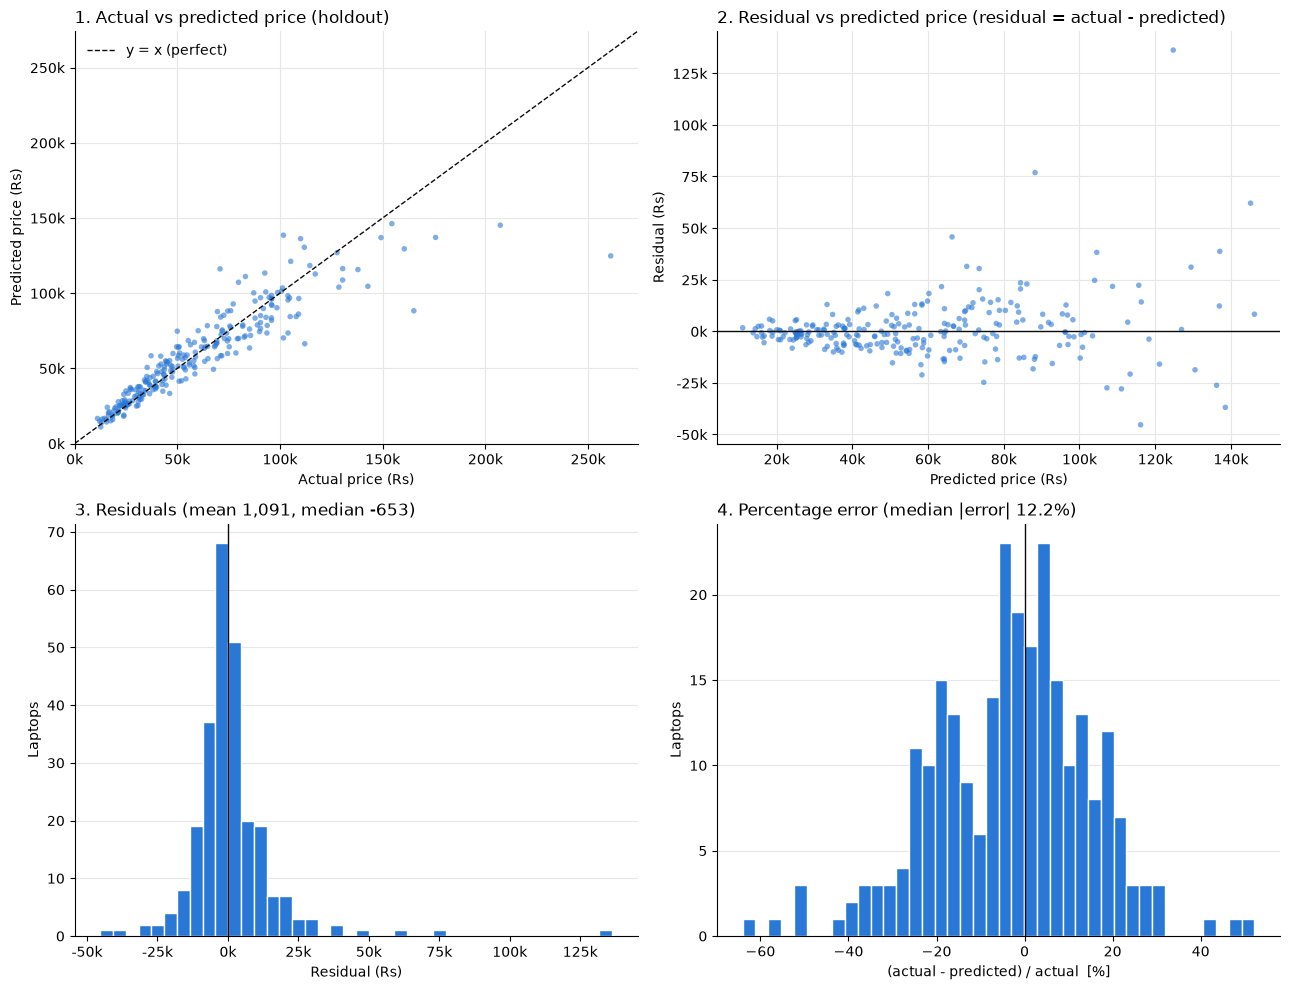

Share of holdout laptops predicted within 10% / 20% / 30%: 45% / 76% / 93%


In [20]:
best_name = cv_summary['CV R2 log (mean)'].idxmax()
print('Best candidate by repeated CV:', best_name)

ea = raw.loc[idx_test, ['Company', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Gpu', 'ScreenResolution', 'Inches', 'OpSys', 'Weight']].copy()
ea['Company_grouped'] = d.loc[idx_test, 'Company_grouped']
ea['Actual'] = price.loc[idx_test]
ea['Predicted'] = np.exp(preds[best_name])
ea['Residual'] = ea['Actual'] - ea['Predicted']              # positive = model UNDER-predicts
ea['Abs error'] = ea['Residual'].abs()
ea['Pct error'] = ea['Residual'] / ea['Actual'] * 100         # signed: positive = under-prediction
ea['Abs pct error'] = ea['Pct error'].abs()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
ax = axes[0, 0]
ax.scatter(ea['Actual'], ea['Predicted'], s=16, color=BLUE, alpha=0.6, edgecolor='none')
lim = [0, ea[['Actual', 'Predicted']].max().max() * 1.05]
ax.plot(lim, lim, color=INK, linewidth=1, linestyle='--', label='y = x (perfect)')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title('1. Actual vs predicted price (holdout)', loc='left')
ax.set_xlabel('Actual price (Rs)'); ax.set_ylabel('Predicted price (Rs)')
ax.xaxis.set_major_formatter(rupees); ax.yaxis.set_major_formatter(rupees); ax.legend(frameon=False)
style(ax, 'both')

ax = axes[0, 1]
ax.scatter(ea['Predicted'], ea['Residual'], s=16, color=BLUE, alpha=0.6, edgecolor='none')
ax.axhline(0, color=INK, linewidth=1)
ax.set_title('2. Residual vs predicted price (residual = actual - predicted)', loc='left')
ax.set_xlabel('Predicted price (Rs)'); ax.set_ylabel('Residual (Rs)')
ax.xaxis.set_major_formatter(rupees); ax.yaxis.set_major_formatter(rupees)
style(ax, 'both')

ax = axes[1, 0]
ax.hist(ea['Residual'], bins=40, color=BLUE, edgecolor='white')
ax.axvline(0, color=INK, linewidth=1)
ax.set_title(f"3. Residuals (mean {ea['Residual'].mean():,.0f}, median {ea['Residual'].median():,.0f})", loc='left')
ax.set_xlabel('Residual (Rs)'); ax.set_ylabel('Laptops'); ax.xaxis.set_major_formatter(rupees)
style(ax)

ax = axes[1, 1]
ax.hist(ea['Pct error'], bins=40, color=BLUE, edgecolor='white')
ax.axvline(0, color=INK, linewidth=1)
ax.set_title(f"4. Percentage error (median |error| {ea['Abs pct error'].median():.1f}%)", loc='left')
ax.set_xlabel('(actual - predicted) / actual  [%]'); ax.set_ylabel('Laptops')
style(ax)
plt.tight_layout()
fig.savefig('final_error_plots.png', dpi=120, bbox_inches='tight')
plt.show()

within = {t: (ea['Abs pct error'] <= t).mean() for t in (10, 20, 30)}
print('Share of holdout laptops predicted within 10% / 20% / 30%:', ' / '.join(f'{v:.0%}' for v in within.values()))

In [21]:
# 5-7. Error by TypeName, company group and actual-price band
bands = [0, 30000, 60000, 100000, np.inf]
band_labels = ['Budget (<30k)', 'Mid-range (30-60k)', 'Premium (60-100k)', 'Very expensive (>100k)']
ea['Price band'] = pd.cut(ea['Actual'], bands, labels=band_labels, right=False)

def by(col):
    t = ea.groupby(col, observed=True).agg(Laptops=('Actual', 'size'), Avg_price=('Actual', 'mean'), MAE=('Abs error', 'mean'),
                                           MAPE=('Abs pct error', 'mean'), Median_APE=('Abs pct error', 'median'),
                                           Mean_signed_pct=('Pct error', 'mean'))
    return t.round(1)

by_type, by_company, by_band = by('TypeName'), by('Company_grouped'), by('Price band')
print('Mean_signed_pct > 0 means the model UNDER-predicts on average; < 0 means it OVER-predicts.\n')
print(by_type.sort_values('MAE', ascending=False).to_string(), '\n')
print(by_company.sort_values('MAE', ascending=False).to_string(), '\n')
print(by_band.to_string())

Mean_signed_pct > 0 means the model UNDER-predicts on average; < 0 means it OVER-predicts.

                    Laptops  Avg_price      MAE  MAPE  Median_APE  Mean_signed_pct
TypeName                                                                          
Workstation               9   103885.1  19275.6  18.0        22.0            -12.1
Ultrabook                37    84137.6  12766.5  15.9        13.8             -1.4
Gaming                   39    83745.5  11817.7  14.7        10.9             -5.7
2 in 1 Convertible       21    73197.7  10167.4  15.5        12.8              0.5
Netbook                   4    50534.7   9561.6  21.5        17.6             -5.6
Notebook                148    42414.4   5988.0  12.5        11.1             -2.8 

                 Laptops  Avg_price      MAE  MAPE  Median_APE  Mean_signed_pct
Company_grouped                                                                
HP                    40    60163.7  12091.8  16.7        12.2             -3.6
Le

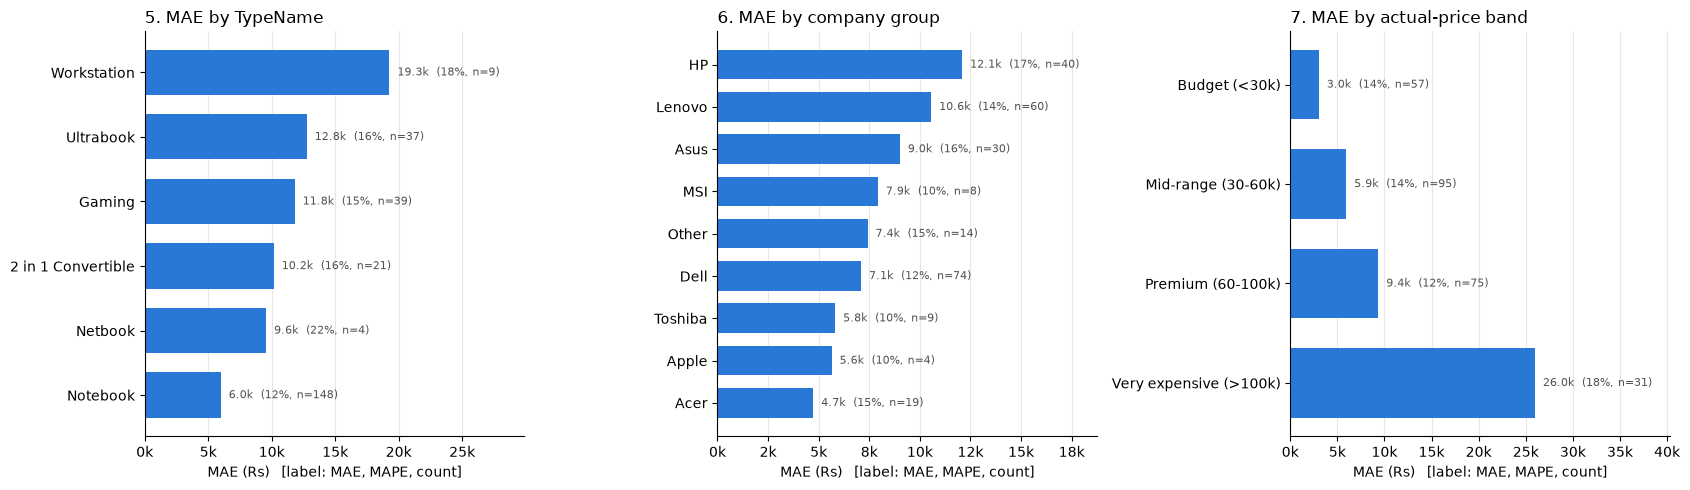

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, t) in zip(axes, [('5. MAE by TypeName', by_type.sort_values('MAE')),
                                 ('6. MAE by company group', by_company.sort_values('MAE')),
                                 ('7. MAE by actual-price band', by_band.iloc[::-1])]):
    ax.barh(t.index.astype(str), t['MAE'], color=BLUE, height=0.7)
    for yp, (m, n_, p) in enumerate(zip(t['MAE'], t['Laptops'], t['MAPE'])):
        ax.text(m, yp, f'  {m/1000:.1f}k  ({p:.0f}%, n={n_})', va='center', fontsize=8, color=INK2)
    ax.set_title(title, loc='left')
    ax.set_xlabel('MAE (Rs)   [label: MAE, MAPE, count]')
    ax.xaxis.set_major_formatter(rupees)
    ax.set_xlim(right=t['MAE'].max() * 1.55)
    style(ax, 'x')
plt.tight_layout()
fig.savefig('final_error_by_group.png', dpi=120, bbox_inches='tight')
plt.show()

In [23]:
# 8. The 20 largest absolute errors
top20 = ea.sort_values('Abs error', ascending=False).head(20)
show = top20[['Company', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Gpu', 'ScreenResolution', 'OpSys', 'Weight',
              'Actual', 'Predicted', 'Abs error', 'Pct error']].copy()
for c in ['Actual', 'Predicted', 'Abs error']:
    show[c] = show[c].round(0).astype(int)
show['Pct error'] = show['Pct error'].round(1)
show

,Company,TypeName,Cpu,Ram,Memory,Gpu,ScreenResolution,OpSys,Weight,Actual,Predicted,Abs error,Pct error
610,Lenovo,Notebook,Intel Xeon E3-1535M v6 3.1GHz,32GB,1TB SSD,Nvidia Quadro M2200M,IPS Panel 4K Ultra HD 3840x2160,Windows 10,2.5kg,261019,124759,136260,52.2
911,HP,Ultrabook,Intel Core M 6Y75 1.2GHz,8GB,240GB SSD,Intel HD Graphics 515,4K Ultra HD / Touchscreen 3840x2160,Windows 10,1.09kg,165168,88268,76900,46.6
238,Asus,Gaming,Intel Core i7 7820HK 2.9GHz,32GB,512GB SSD + 1TB HDD,Nvidia GeForce GTX 1080,Full HD 1920x1080,Windows 10,4.7kg,207259,145185,62074,29.9
1045,HP,Notebook,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD + 500GB HDD,Intel HD Graphics 520,Full HD 1920x1080,Windows 10,1.84kg,112066,66343,45723,40.8
1068,Dell,Gaming,Intel Core i7 6700HQ 2.6GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 970M,4K Ultra HD 3840x2160,Windows 10,3.21kg,70809,116139,45330,-64.0
744,Lenovo,Workstation,Intel Core i7 7600U 2.8GHz,16GB,1TB SSD,Nvidia Quadro M520M,IPS Panel 4K Ultra HD 3840x2160,Windows 10,2.5kg,175771,137045,38725,22.0
1202,Dell,Ultrabook,Intel Core i7 7500U 2.7GHz,16GB,512GB SSD,Intel HD Graphics 620,Quad HD+ / Touchscreen 3200x1800,Windows 10,1.2kg,142790,104565,38225,26.8
692,HP,Workstation,Intel Core i7 7700HQ 2.8GHz,8GB,500GB HDD,Nvidia Quadro M1200,Full HD 1920x1080,Windows 10,3.14kg,101658,138521,36863,-36.3
990,HP,Netbook,Intel Core M 6Y75 1.2GHz,8GB,512GB SSD,Intel HD Graphics 515,Full HD 1920x1080,Windows 10,0.97kg,101658,70228,31430,30.9
530,Dell,Gaming,Intel Core i7 7700HQ 2.8GHz,16GB,128GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,IPS Panel Full HD 1920x1080,Windows 10,4.42kg,160520,129462,31058,19.3


In [24]:
# Are the top-20 errors concentrated anywhere? Compare their make-up with the whole holdout
comp = pd.DataFrame({
    'Top-20 share': top20['Price band'].value_counts(normalize=True),
    'Holdout share': ea['Price band'].value_counts(normalize=True)}).round(2)
print(comp.to_string(), '\n')
print(pd.DataFrame({'Top-20 share': top20['TypeName'].value_counts(normalize=True),
                    'Holdout share': ea['TypeName'].value_counts(normalize=True)}).fillna(0).round(2).to_string(), '\n')
print('Top-20: under-predicted', (top20['Residual'] > 0).sum(), '| over-predicted', (top20['Residual'] < 0).sum())
print('Correlation of signed % error with actual price (all holdout):', round(ea['Pct error'].corr(np.log(ea['Actual'])), 3))

# Price-noise floor: how different are prices of identical configurations in the data? (a model cannot beat this noise)
same = raw[raw.duplicated(subset=SPEC_COLS, keep=False)].groupby(SPEC_COLS)['Price']
noise = same.apply(lambda p: (np.abs(p - p.mean()) / p).mean() * 100)
print(f'\nIdentical configurations differ from their group mean by {noise.median():.1f}% on median ({len(noise)} groups)')

                        Top-20 share  Holdout share
Price band                                         
Budget (<30k)                   0.00           0.22
Mid-range (30-60k)              0.05           0.37
Premium (60-100k)               0.15           0.29
Very expensive (>100k)          0.80           0.12 

                    Top-20 share  Holdout share
TypeName                                       
2 in 1 Convertible          0.10           0.08
Gaming                      0.30           0.15
Netbook                     0.05           0.02
Notebook                    0.20           0.57
Ultrabook                   0.15           0.14
Workstation                 0.20           0.03 

Top-20: under-predicted 14 | over-predicted 6
Correlation of signed % error with actual price (all holdout): 0.41

Identical configurations differ from their group mean by 4.1% on median (45 groups)


## 8. Train/test leakage checks

In [25]:
checks = []
def check(label, ok):
    checks.append((label, 'PASS' if ok else 'FAIL'))
    assert ok, label

# 1. No duplicate observations across train and test
tr_rows = raw.loc[idx_train, SPEC_COLS + ['Price']].apply(tuple, axis=1)
te_rows = raw.loc[idx_test, SPEC_COLS + ['Price']].apply(tuple, axis=1)
check('No exact duplicate row appears in both train and holdout', not te_rows.isin(set(tr_rows)).any())
check('No identical configuration (ignoring price) appears in both train and holdout',
      set(groups[idx_train]).isdisjoint(set(groups[idx_test])))
check('Train and holdout indices are disjoint and cover all rows',
      set(idx_train).isdisjoint(idx_test) and len(idx_train) + len(idx_test) == len(d))
n_feat_overlap = pd.merge(X_train.drop_duplicates(), X_test.drop_duplicates(), how='inner').shape[0]
print(f'(Info) holdout rows whose ENGINEERED features also occur in train: {n_feat_overlap} '
      '- raw specs differ (e.g. GPU model/weight) but map to identical features; not a leak of the target.')

# 2. Price is never an input
check('Price / log price not among model inputs', not any('price' in c.lower() for c in FEATURES))
for name, m in fitted.items():
    cols = m.feature_names_in_ if hasattr(m, 'feature_names_in_') else m.estimators_[0].feature_names_in_
    check(f'{name}: fitted input columns == the 18 features', list(cols) == FEATURES)
check('Features built from data without the Price column', 'Price' not in raw_X.columns)

# 3. Encoders fitted only on training data (they live inside the Pipeline, and the Pipeline was fitted on X_train only)
enc = fitted['XGBoost'].named_steps['preprocess'].named_transformers_['cat']
train_cats = [set(X_train[c].unique()) for c in FINAL_CAT]
check('OneHotEncoder categories == categories seen in training rows',
      all(set(cats) == tc for cats, tc in zip(enc.categories_, train_cats)))
unseen = {c: sorted(set(X_test[c]) - set(X_train[c])) for c in FINAL_CAT if set(X_test[c]) - set(X_train[c])}
print('(Info) categories present only in the holdout (encoded as all-zeros via handle_unknown):', unseen or 'none')

# 4. Company grouping rule uses only training counts
recomputed = company_counts_train[company_counts_train < 10].index
check('Rare-company list derived from training rows only', set(recomputed) == set(rare_companies)
      and company_counts_train.sum() == len(idx_train))

# 5. Tuning / CV never saw holdout rows
test_positions_in_train = set()   # folds index into X_train, which contains no holdout rows
check('Tuning folds only index training rows', all(max(np.r_[a, b]) < len(X_train) for a, b in tune_folds))
check('Repeated-CV folds only index training rows', all(max(np.r_[a, b]) < len(X_train) for a, b in rep_folds))
check('Tuning folds are group-aware (no config in both fold-train and fold-validation)',
      all(set(g_train.iloc[a]).isdisjoint(g_train.iloc[b]) for a, b in tune_folds))
check('Best model chosen from CV before the holdout was scored', best_name == cv_summary['CV R2 log (mean)'].idxmax())

pd.DataFrame(checks, columns=['Check', 'Result'])

(Info) holdout rows whose ENGINEERED features also occur in train: 12 - raw specs differ (e.g. GPU model/weight) but map to identical features; not a leak of the target.
(Info) categories present only in the holdout (encoded as all-zeros via handle_unknown): none


,Check,Result
0,No exact duplicate row appears in bo...,PASS
1,No identical configuration (ignoring...,PASS
2,Train and holdout indices are disjoi...,PASS
3,Price / log price not among model in...,PASS
4,XGBoost: fitted input columns == the...,PASS
5,Gradient Boosting: fitted input colu...,PASS
6,Voting (XGB+GB+HistGB+RF): fitted in...,PASS
7,Features built from data without the...,PASS
8,OneHotEncoder categories == categori...,PASS
9,Rare-company list derived from train...,PASS


## 9. Voting vs XGBoost in practice

In [26]:
def size_kb(model):
    return len(pickle.dumps(model)) / 1024

def single_predict_ms(model, reps=200):
    row = X_test.iloc[[0]]
    model.predict(row)                                   # warm-up
    times = []
    for _ in range(reps):
        t = time.perf_counter(); model.predict(row); times.append(time.perf_counter() - t)
    return np.median(times) * 1000

def batch_predict_ms(model, reps=20):
    times = []
    for _ in range(reps):
        t = time.perf_counter(); model.predict(X_test); times.append(time.perf_counter() - t)
    return np.median(times) * 1000

practical = pd.DataFrame({name: {
    'Holdout R2 (log)': holdout.loc[name, 'R2 (log price)'],
    'Holdout MAE (Rs)': holdout.loc[name, 'MAE (Rs)'],
    'CV R2 log mean ± std': f"{cv_summary.loc[name, 'CV R2 log (mean)']:.4f} ± {cv_summary.loc[name, 'CV R2 log (std)']:.4f}",
    'Model size (KB, pickled)': round(size_kb(m)),
    'Predict 1 laptop (ms)': round(single_predict_ms(m), 2),
    f'Predict {len(X_test)} laptops (ms)': round(batch_predict_ms(m), 1),
    'Fit time (s)': None,
} for name, m in fitted.items()}).T

for name in fitted:
    t = time.perf_counter(); clone(candidates[name]).fit(X_train, y_train)
    practical.loc[name, 'Fit time (s)'] = round(time.perf_counter() - t, 1)
practical['Libraries needed'] = ['xgboost + sklearn', 'sklearn', 'xgboost + sklearn']
practical['Sub-models'] = [1, 1, 4]
practical

,Holdout R2 (log),Holdout MAE (Rs),CV R2 log mean ± std,"Model size (KB, pickled)",Predict 1 laptop (ms),Predict 258 laptops (ms),Fit time (s),Libraries needed,Sub-models
XGBoost,0.915952,8700.476938,0.8974 ± 0.0138,2003,1.81,3.4,0.1,xgboost + sklearn,1
Gradient Boosting,0.914569,8690.691794,0.8951 ± 0.0136,1609,1.87,5.0,0.3,sklearn,1
Voting (XGB+GB+HistGB+RF),0.914975,8646.167715,0.8959 ± 0.0129,43334,60.17,80.7,4.0,xgboost + sklearn,4


## 10. Summary numbers

In [27]:
print(f'Raw rows {n0} -> minus ARM row {n1} -> minus {n1 - n2} exact duplicates = {n2} usable observations')
print(f'Train {len(idx_train)} | Final holdout {len(idx_test)} | split seed {SPLIT_SEED}, grouped by configuration')
print()
summary = holdout[['R2 (log price)', 'R2 (price)', 'MAE (Rs)', 'RMSE (Rs)', 'MAPE (%)', 'Median APE (%)']].copy()
summary['CV R2 log (mean ± std)'] = [f"{cv_summary.loc[n, 'CV R2 log (mean)']:.4f} ± {cv_summary.loc[n, 'CV R2 log (std)']:.4f}" for n in summary.index]
summary['CV MAE Rs (mean ± std)'] = [f"{cv_summary.loc[n, 'CV MAE Rs (mean)']:,.0f} ± {cv_summary.loc[n, 'CV MAE Rs (std)']:,.0f}" for n in summary.index]
summary.round(4)

Raw rows 1303 -> minus ARM row 1302 -> minus 29 exact duplicates = 1273 usable observations
Train 1015 | Final holdout 258 | split seed 42, grouped by configuration



,R2 (log price),R2 (price),MAE (Rs),RMSE (Rs),MAPE (%),Median APE (%),CV R2 log (mean ± std),CV MAE Rs (mean ± std)
Model,,,,,,,,
XGBoost,0.9160,0.8233,8700.4769,15275.0533,13.9160,12.2205,0.8974 ± 0.0138,"9,565 ± 1,002"
Gradient Boosting,0.9146,0.8381,8690.6918,14624.4075,14.0061,11.6816,0.8951 ± 0.0136,"9,728 ± 1,067"
Voting (XGB+GB+HistGB+RF),0.9150,0.8234,8646.1677,15272.2628,13.8368,10.8951,0.8959 ± 0.0129,"9,660 ± 1,032"
